# 5 · The closed loop, and an honest benchmark

Putting it together: a Latin hypercube for round 0, then **score → learn → choose** in batches of 6.
Then the question that matters: **with the same number of experiments, does the loop actually beat simpler strategies?**

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # use the local package without installing it
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nanobo as nb

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 3)

In [2]:
campaign = nb.run_bo(n_init=6, batch=6, n_rounds=4, seed=0)
campaign.round(3).head(12)

,round,reason,conc_M,ratio_OA_Fe,temp_C,size_nm,disp_pct,score,true_score
0,0,LHS,0.148,3.487,306.394,8.736,7.349,0.535,0.571
1,0,LHS,0.216,2.458,313.915,14.471,59.260,0.000,0.000
2,0,LHS,0.233,1.847,309.709,15.062,70.818,0.000,0.000
3,0,LHS,0.094,3.789,286.648,5.108,44.344,0.000,0.000
4,0,LHS,0.264,4.978,288.469,0.732,96.415,0.000,0.000
5,0,LHS,0.084,1.091,296.390,12.487,53.870,0.000,0.000
6,1,model,0.158,1.123,284.702,7.733,17.113,0.000,0.000
7,1,model,0.156,4.621,319.075,9.115,7.084,0.659,0.742
8,1,model,0.151,1.064,316.720,15.890,180.799,0.000,0.000
9,1,model,0.137,1.902,319.503,14.320,131.812,0.000,0.000


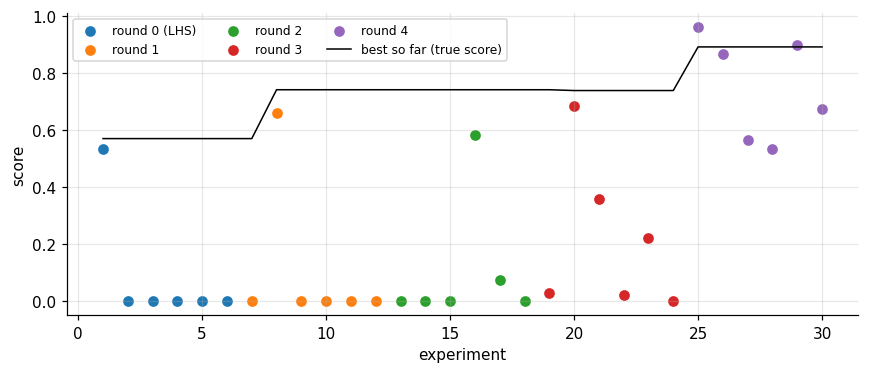

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for rnd, g in campaign.groupby("round"):
    ax.scatter(g.index + 1, g["score"], label=f"round {rnd}" + (" (LHS)" if rnd == 0 else ""))
ax.plot(np.arange(1, len(campaign) + 1), nb.best_so_far(campaign), "k-", lw=1, label="best so far (true score)")
ax.set_xlabel("experiment"); ax.set_ylabel("score"); ax.legend(fontsize=8, ncol=3); plt.tight_layout(); plt.show()

## Benchmark: four strategies, the same budget of 30 experiments, 20 repetitions

* **BO** — 6 LHS + 4 rounds of 6 chosen by EI + kriging believer
* **LHS** — one Latin hypercube of 30 experiments
* **random** — 30 random recipes
* **OFAT** — one factor at a time: scan concentration (10 levels), keep the best, then the ratio, then the temperature

The metric is what a chemist would take home: the **true** score of the recipe with the best **measured** score
(the virtual lab knows the truth; a real lab would confirm it with repeats). This takes about a minute.

In [4]:
N, SEEDS = 30, range(20)
strategies = {
    "BO": lambda s: nb.run_bo(seed=s),
    "LHS": lambda s: nb.run_design("lhs", N, seed=s),
    "random": lambda s: nb.run_design("random", N, seed=s),
    "OFAT": lambda s: nb.run_ofat(N, seed=s),
}
curves = {k: np.array([nb.best_so_far(f(s)) for s in SEEDS]) for k, f in strategies.items()}
summary = pd.DataFrame({k: np.percentile(v[:, -1], [25, 50, 75]) for k, v in curves.items()},
                       index=["25th pct", "median", "75th pct"]).T
summary.round(3)

,25th pct,median,75th pct
BO,0.699,0.891,0.945
LHS,0.484,0.733,0.842
random,0.442,0.692,0.883
OFAT,0.481,0.495,0.519


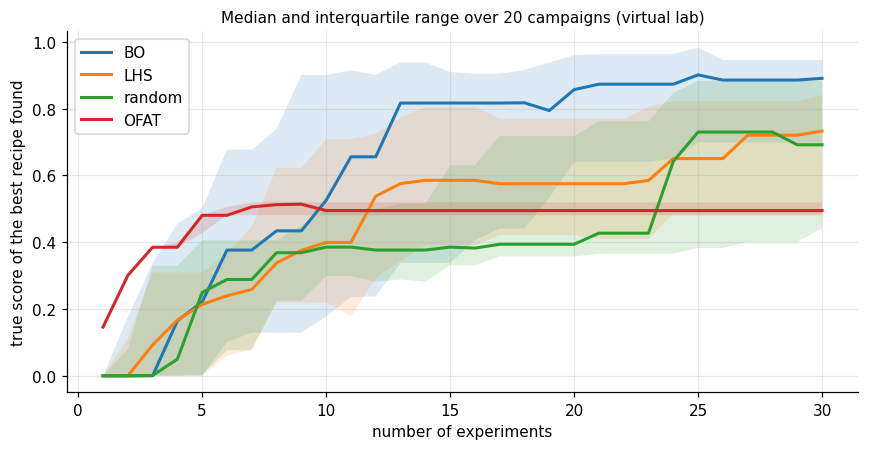

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.2))
n = np.arange(1, N + 1)
for k, v in curves.items():
    q25, q50, q75 = np.percentile(v, [25, 50, 75], axis=0)
    ax.plot(n, q50, lw=2, label=k); ax.fill_between(n, q25, q75, alpha=0.15)
ax.set_xlabel("number of experiments"); ax.set_ylabel("true score of the best recipe found")
ax.set_title("Median and interquartile range over 20 campaigns (virtual lab)", fontsize=10)
ax.legend(); plt.tight_layout()
Path("../docs/figures").mkdir(parents=True, exist_ok=True)
plt.savefig("../docs/figures/benchmark.png", dpi=150); plt.show()

## Reading the result honestly

* **OFAT** stops early: the best ligand ratio depends on the temperature (an interaction), so scanning one variable at a
  time ends on a ridge far from the optimum. This is the classic weakness of manual optimisation.
* **BO** is no better than the hypercube during round 0 (it *is* a hypercube); its advantage appears once the model
  starts choosing.
* The spread is large: with 30 noisy experiments, some campaigns miss. Conclusions need **repetitions**, and in a real
  lab, confirmation of the final recipe by repeats.
* This toy problem has 3 variables and one objective; real campaigns add variables, constraints and several targets.

## Centre points: paying a few experiments to measure the noise

Same budget, but one experiment per round is spent on the centre point.

In [6]:
final_c = np.array([nb.best_so_far(nb.run_bo(seed=s, n_centre=1))[-1] for s in SEEDS])
print(f"BO without centre points: median {np.median(curves['BO'][:, -1]):.3f}")
print(f"BO with 1 centre point per round: median {np.median(final_c):.3f}")

BO without centre points: median 0.891
BO with 1 centre point per round: median 0.793


On this toy problem the noise is small and constant, so spending one experiment in six on the centre point
clearly costs performance: fewer experiments go where the model wants them. On a real
platform they are what tells you whether the noise is small, whether it drifts between rounds (new precursor lot,
ageing seeds), and whether the model can be trusted — the virtual lab can simulate such a batch effect with
`VirtualLab(batch_sd=...)`, a good exercise.

## Going further

* Several objectives → a Pareto front instead of one score (e.g. `qNEHVI` in BoTorch).
* Noisy data → *noisy* expected improvement (`qNEI`), joint batch selection (`optimize_acqf(q=...)`).
* Real campaigns → log everything (recipe as executed, time, batch of reagents) and flag suspicious experiments.